In [1]:
!pip install lgb


ERROR: Could not find a version that satisfies the requirement lgb (from versions: none)
ERROR: No matching distribution found for lgb


In [2]:
import os
import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    mean_absolute_error,
    mean_squared_error
)
from sklearn.preprocessing import StandardScaler

# Set visualization styles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

In [3]:
# Load the raw Online Retail II dataset
DATA_PATH = "../data/raw/online_retail_II.csv"

df_raw = pd.read_csv(
    DATA_PATH,
    usecols=["Invoice", "StockCode", "Quantity", "InvoiceDate", "Price"]
)

print(f"Raw shape: {df_raw.shape}")
df_raw.head()

Raw shape: (1067371, 5)


,Invoice,StockCode,Quantity,InvoiceDate,Price
0,489434,85048,12,2009-12-01 07:45:00,6.95
1,489434,79323P,12,2009-12-01 07:45:00,6.75
2,489434,79323W,12,2009-12-01 07:45:00,6.75
3,489434,22041,48,2009-12-01 07:45:00,2.10
4,489434,21232,24,2009-12-01 07:45:00,1.25


In [4]:
# 1. Remove cancellations (Invoice codes starting with 'C') and invalid prices/quantities
df = df_raw[~df_raw["Invoice"].astype(str).str.startswith("C")].copy()
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)].copy()

# 2. Remove extreme wholesale anomaly spikes (> 200 units, covers the 99th percentile)
df = df[df["Quantity"] <= 200].copy()

# 3. Normalize InvoiceDate to daily dates
df["date"] = pd.to_datetime(df["InvoiceDate"]).dt.normalize()

print(f"Cleaned transaction shape: {df.shape}")
df.head()

Cleaned transaction shape: (1037585, 6)


,Invoice,StockCode,Quantity,InvoiceDate,Price,date
0,489434,85048,12,2009-12-01 07:45:00,6.95,2009-12-01
1,489434,79323P,12,2009-12-01 07:45:00,6.75,2009-12-01
2,489434,79323W,12,2009-12-01 07:45:00,6.75,2009-12-01
3,489434,22041,48,2009-12-01 07:45:00,2.10,2009-12-01
4,489434,21232,24,2009-12-01 07:45:00,1.25,2009-12-01


In [5]:
# Select top 20 SKUs by repeat invoice frequency (consistent consumer demand)
top_skus = df.groupby("StockCode")["Invoice"].nunique().nlargest(20).index
df_top = df[df["StockCode"].isin(top_skus)].copy()

# Aggregate daily units sold and average price per SKU
daily = (
    df_top.groupby(["StockCode", "date"])
    .agg(sales=("Quantity", "sum"), avg_price=("Price", "mean"))
    .reset_index()
)

# Build a continuous daily grid (fill unrecorded zero-sales days)
all_skus = daily["StockCode"].unique()
all_dates = pd.date_range(daily["date"].min(), daily["date"].max(), freq="D")
full_idx = pd.MultiIndex.from_product([all_skus, all_dates], names=["StockCode", "date"]).to_frame().reset_index(drop=True)

daily_complete = pd.merge(full_idx, daily, on=["StockCode", "date"], how="left")
daily_complete["sales"] = daily_complete["sales"].fillna(0).astype(np.int32)
daily_complete["avg_price"] = daily_complete.groupby("StockCode")["avg_price"].transform(lambda x: x.ffill().bfill())
daily_complete = daily_complete.sort_values(by=["StockCode", "date"]).reset_index(drop=True)

print(f"Daily grid records: {len(daily_complete)}")
daily_complete.head()

Daily grid records: 14780


,StockCode,date,sales,avg_price
0,20725,2009-12-01,164,2.058333
1,20725,2009-12-02,12,2.407143
2,20725,2009-12-03,31,2.091667
3,20725,2009-12-04,73,1.890909
4,20725,2009-12-05,0,1.890909


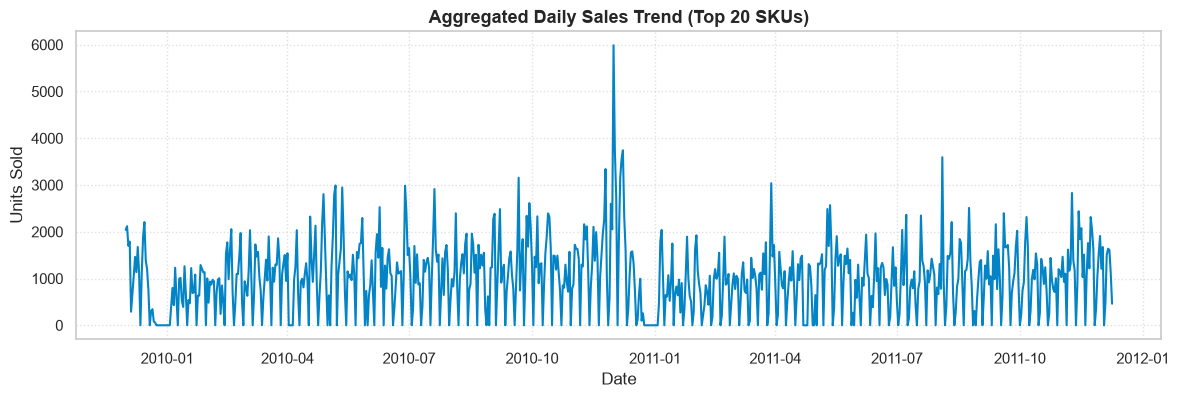

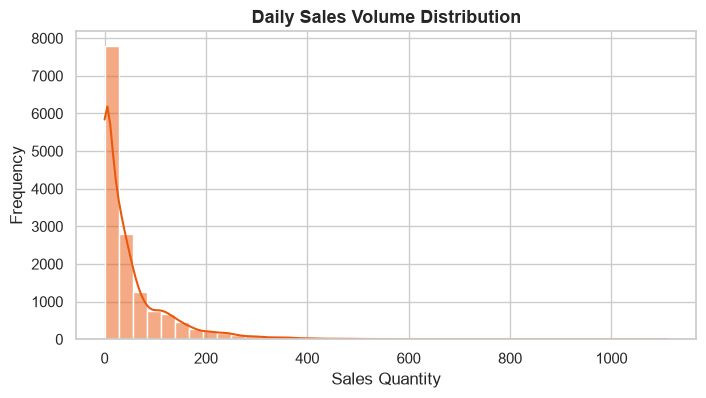

In [6]:
# Plot total daily sales velocity over time
total_daily = daily_complete.groupby("date")["sales"].sum().reset_index()

plt.figure(figsize=(14, 4))
plt.plot(total_daily["date"], total_daily["sales"], color="#0284c7", linewidth=1.5)
plt.title("Aggregated Daily Sales Trend (Top 20 SKUs)", fontsize=13, fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

# Distribution of sales (showing zero-inflation and skewness)
plt.figure(figsize=(8, 4))
sns.histplot(daily_complete["sales"], bins=40, kde=True, color="#ea580c")
plt.title("Daily Sales Volume Distribution", fontsize=13, fontweight="bold")
plt.xlabel("Sales Quantity")
plt.ylabel("Frequency")
plt.show()

In [7]:
horizon = 14
lags = [14, 21, 28]
windows = [7, 14, 28]

df_feat = daily_complete.copy()

# Horizon-shifted lag features (no data leakage)
for lag in lags:
    df_feat[f"sales_lag_{lag}"] = df_feat.groupby("StockCode")["sales"].shift(lag)

# Horizon-shifted rolling statistics
for w in windows:
    df_feat[f"sales_roll_mean_{w}"] = df_feat.groupby("StockCode")["sales"].transform(
        lambda x: x.shift(horizon).rolling(w).mean()
    )
    df_feat[f"sales_roll_std_{w}"] = df_feat.groupby("StockCode")["sales"].transform(
        lambda x: x.shift(horizon).rolling(w).std()
    )
    # Zero-demand ratio in rolling window
    df_feat[f"zero_ratio_{w}"] = df_feat.groupby("StockCode")["sales"].transform(
        lambda x: (x.shift(horizon) == 0).rolling(w).mean()
    )

# Calendar features
df_feat["day_of_week"] = df_feat["date"].dt.day_of_week.astype(np.int8)
df_feat["is_weekend"] = df_feat["day_of_week"].isin([5, 6]).astype(np.int8)
df_feat["month"] = df_feat["date"].dt.month.astype(np.int8)
df_feat["day_of_month"] = df_feat["date"].dt.day.astype(np.int8)

# Drop initial rows with NaN values resulting from 28-day shifts
df_feat = df_feat.dropna().reset_index(drop=True)
print(f"Engineered dataset shape: {df_feat.shape}")
df_feat.head()

Engineered dataset shape: (13960, 20)


,StockCode,date,sales,avg_price,sales_lag_14,sales_lag_21,sales_lag_28,sales_roll_mean_7,sales_roll_std_7,zero_ratio_7,sales_roll_mean_14,sales_roll_std_14,zero_ratio_14,sales_roll_mean_28,sales_roll_std_28,zero_ratio_28,day_of_week,is_weekend,month,day_of_month
0,20725,2010-01-11,29,3.752000,0.0,110.0,60.0,0.142857,0.377964,0.857143,20.500000,32.315155,0.500000,34.892857,44.138955,0.321429,0,0,1,11
1,20725,2010-01-12,3,2.930000,0.0,1.0,11.0,0.000000,0.000000,1.000000,19.714286,32.695397,0.571429,29.035714,36.611557,0.357143,1,0,1,12
2,20725,2010-01-13,12,3.356667,0.0,0.0,55.0,0.000000,0.000000,1.000000,15.785714,31.408423,0.642857,28.607143,36.887556,0.392857,2,0,1,13
3,20725,2010-01-14,112,2.880000,0.0,0.0,26.0,0.000000,0.000000,1.000000,13.928571,31.526458,0.714286,27.500000,37.276246,0.428571,3,0,1,14
4,20725,2010-01-15,10,1.650000,0.0,0.0,44.0,0.000000,0.000000,1.000000,10.785714,30.473642,0.785714,24.892857,36.521267,0.464286,4,0,1,15


In [8]:
# Split on a strict date boundary (last 14 days reserved for holdout test set)
val_days = 14
split_date = df_feat["date"].max() - pd.Timedelta(days=val_days)

train_df = df_feat[df_feat["date"] <= split_date].copy()
test_df = df_feat[df_feat["date"] > split_date].copy()

feature_cols = [
    c for c in df_feat.columns 
    if "lag" in c or "roll" in c or "zero_ratio" in c or c in ["avg_price", "day_of_week", "is_weekend", "month", "day_of_month"]
]
target_col = "sales"

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]

print(f"Training records: {X_train.shape[0]} | Test records: {X_test.shape[0]}")
print(f"Features: {feature_cols}")

Training records: 13680 | Test records: 280
Features: ['avg_price', 'sales_lag_14', 'sales_lag_21', 'sales_lag_28', 'sales_roll_mean_7', 'sales_roll_std_7', 'zero_ratio_7', 'sales_roll_mean_14', 'sales_roll_std_14', 'zero_ratio_14', 'sales_roll_mean_28', 'sales_roll_std_28', 'zero_ratio_28', 'day_of_week', 'is_weekend', 'month', 'day_of_month']


In [9]:
# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Apply log1p transform on target to stabilize variance
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

In [10]:
# Train regularized LightGBM Regressor
model = lgb.LGBMRegressor(
    objective="regression",
    learning_rate=0.03,
    num_leaves=24,
    max_depth=5,
    min_child_samples=25,
    colsample_bytree=0.85,
    subsample=0.85,
    reg_alpha=1.0,
    reg_lambda=2.0,
    n_estimators=350,
    random_state=42,
    verbose=-1
)

model.fit(
    X_train_scaled, 
    y_train_log, 
    eval_set=[(X_test_scaled, y_test_log)],
    callbacks=[lgb.early_stopping(stopping_rounds=40, verbose=False)]
)

print(f"Best Iteration: {model.best_iteration_}")

C:\Users\prath\Desktop\retail-demand-forecasting-system\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Best Iteration: 168


In [11]:
# Generate predictions and reverse log1p scaling
preds_log = model.predict(X_test_scaled)
y_pred = np.maximum(np.expm1(preds_log), 0)

# 1. Regression Metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
wmape = (np.sum(np.abs(y_test.values - y_pred)) / np.sum(y_test.values)) * 100

print("=================================================")
print("          REGRESSION MODEL PERFORMANCE           ")
print("=================================================")
print(f"MAE   : {mae:.2f} units")
print(f"RMSE  : {rmse:.2f} units")
print(f"WMAPE : {wmape:.2f}%")

# 2. Demand Event Classification Metrics (Demand Day > 0.5 vs. Zero-Sales Day)
y_test_bin = (y_test.values > 0.5).astype(int)
y_pred_bin = (y_pred > 0.5).astype(int)

print("\n=================================================")
print("         DEMAND DETECTION CLASSIFICATION         ")
print("=================================================")
print(f"Accuracy: {accuracy_score(y_test_bin, y_pred_bin) * 100:.2f}%\n")
print(classification_report(y_test_bin, y_pred_bin, target_names=["Zero Day", "Demand Day"]))

          REGRESSION MODEL PERFORMANCE           
MAE   : 33.22 units
RMSE  : 72.22 units
WMAPE : 64.21%

         DEMAND DETECTION CLASSIFICATION         
Accuracy: 98.93%

              precision    recall  f1-score   support

    Zero Day       1.00      0.93      0.96        43
  Demand Day       0.99      1.00      0.99       237

    accuracy                           0.99       280
   macro avg       0.99      0.97      0.98       280
weighted avg       0.99      0.99      0.99       280



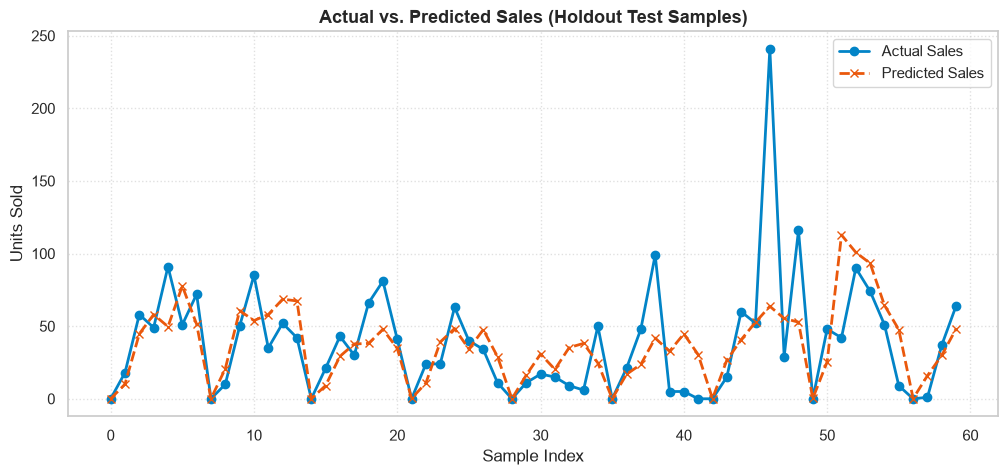

In [12]:
plt.figure(figsize=(12, 5))
plt.plot(np.arange(len(y_test[:60])), y_test.values[:60], label="Actual Sales", color="#0284c7", marker="o", linewidth=2)
plt.plot(np.arange(len(y_pred[:60])), y_pred[:60], label="Predicted Sales", color="#ea580c", linestyle="--", marker="x", linewidth=2)
plt.title("Actual vs. Predicted Sales (Holdout Test Samples)", fontsize=13, fontweight="bold")
plt.xlabel("Sample Index")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

In [13]:
# Ensure directories exist and dump model artifacts
os.makedirs("../models", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../data/sample", exist_ok=True)

# 1. Save model and scaler via joblib
joblib.dump(model, "../models/lightgbm_model.pkl")
joblib.dump(scaler, "../models/scaler.pkl")

# 2. Save processed dataset and sample for fast cloud loading
daily_complete.to_parquet("../data/processed/daily_sales.parquet", index=False)
daily_complete.head(100).to_csv("../data/sample/sample_sales.csv", index=False)

print("✓ All artifacts saved successfully:")
print("  -> ../models/lightgbm_model.pkl")
print("  -> ../models/scaler.pkl")
print("  -> ../data/processed/daily_sales.parquet")
print("  -> ../data/sample/sample_sales.csv")

✓ All artifacts saved successfully:
  -> ../models/lightgbm_model.pkl
  -> ../models/scaler.pkl
  -> ../data/processed/daily_sales.parquet
  -> ../data/sample/sample_sales.csv
